# H15 Part A · Steps 6–7 · How the side-car will be evaluated

The review of the evaluation in [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§8): what
will be measured on NAVSIM's report logs at step 6, and on nuScenes at step 7. Every metric is shown on
something real, the **pipeline check's checkpoint** (epoch 1 of 12, run `H15.r1`), read on the **select**
logs only. Its numbers are a smoke reading: they show what each metric looks like, not how good the
side-car is. No report-log number is computed here.

1. the metrics, and the matching rule on a toy;
2. what the side-car's output looks like;
3. the current readout, reproduced from the checkpoint;
4. the proposed metrics, prototyped (adopted or not at the review, plan §11 Q4);
5. uncertainty: resampling whole logs;
6. the sight check, in distribution;
7. nuScenes, out of the box: the plan.

Run it with Drive-JEPA's interpreter. It uses a GPU if one is visible (the select pass takes seconds),
else the CPU (minutes).

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import evaluate, navsim_data, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
NAVSIM = Path(cfg.resolve("{data.navsim}"))
RUN = RUNS / "part-a" / "r1-pipeline-v1-s0"
labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
select = np.flatnonzero(np.isin(token_logs, splits["select"]))
proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r"))).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")
run = json.loads((RUN / "run.json").read_text())
recorded = json.loads((RUN / "metrics.jsonl").read_text().splitlines()[0])
model, kept = train_sidecar.load_run(RUN)
print(f"checkpoint: H15.r1, epoch {kept} of a 12-epoch schedule; select: {len(select):,} samples")


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

checkpoint: H15.r1, epoch 1 of a 12-epoch schedule; select: 4,457 samples


## 1. The metrics, and the matching rule

| Group | Metric | Status |
|---|---|---|
| Detection | recall, precision and F1 at 2 m within 30 m; recall per range bin (0–20, 20–30, 30–50 m) and per class | in `evaluate.readout` |
| | AP at 0.5, 1, 2, 4 m per class (threshold-free) | **proposed** (section 4) |
| | hit rate by confidence (calibration); detections against targets per sample | **proposed**; in the readout |
| Boxes | centre error of hits | in the readout |
| | z, size (1 − IoU of aligned boxes) and yaw errors of hits | **proposed** |
| Motion | velocity error of hits; 1 s path ADE/FDE against stationary, constant velocity (its own) and constant velocity (the label's) | in the readout |
| | displacement error: motion apart from position | **proposed** |
| Lead vehicle | gap error to the nearest vehicle ahead (\|y\| ≤ 1.75 m), against the train-mean prior | in the readout |
| Sight | recall with zeroed tokens, and with another log's tokens | `train_sidecar sight` |
| Breakdowns | by city; by ego speed | **proposed** |

**The matching rule** (`evaluate.match`, H04's). A slot is a **detection** when its confidence,
1 − p(none), is at least 0.5; its class is the most likely of the three. Detections are taken in order of
confidence; each takes the nearest still-free target **of its class** within **2 m** (centre, x-y). A
target taken is a hit; a detection that takes nothing is a false alarm.

A toy: three targets (two vehicles, one pedestrian) and five slots.

In [2]:
conf = np.array([0.95, 0.90, 0.80, 0.60, 0.30])
cls = np.array([0, 0, 1, 0, 1])
xy = np.array([[10.4, 0.0], [10.6, 0.3], [20.0, 3.0], [31.0, -2.0], [20.2, 3.1]])
gxy = np.array([[10.0, 0.0], [20.5, 3.0], [32.5, -2.0]])
gcls = np.array([0, 1, 0])
det, tp, hit = evaluate.match(conf, cls, xy, gxy, gcls)
pd.DataFrame(
    {"confidence": conf, "class": [views.CLASS_NAMES[c] for c in cls], "x": xy[:, 0], "y": xy[:, 1],
     "a detection (≥ 0.5)": conf >= evaluate.THR,
     "outcome": ["hit target %d" % list(hit).index(q) if q in hit else ("false alarm" if conf[q] >= evaluate.THR else "—")
                 for q in range(5)]},
    index=[f"slot {q}" for q in range(5)],
)

,confidence,class,x,y,a detection (≥ 0.5),outcome
slot 0,0.95,vehicle,10.4,0.0,True,hit target 0
slot 1,0.90,vehicle,10.6,0.3,True,false alarm
slot 2,0.80,pedestrian,20.0,3.0,True,hit target 1
slot 3,0.60,vehicle,31.0,-2.0,True,hit target 2
slot 4,0.30,pedestrian,20.2,3.1,False,—


Slot 1 is as close to the first vehicle as slot 0, but slot 0 is more confident and takes it: slot 1 is a
false alarm, a **duplicate**. Slot 3 hits the far vehicle 1.5 m off. Slot 4 sits on the pedestrian but is
under the threshold, so it is not a detection. Recall 3 of 3, precision 3 of 4.

## 2. What the side-car's output looks like

The checkpoint's last layer on the select logs, at the readout's threshold. On the image: targets (solid,
class colour) and the 3D boxes of the detections (thin white). From above: targets as outlines, hit
targets filled; detections as dots, green if they hit, red if they are false alarms.

ran on cuda | outputs: {'logits': (4457, 64, 4), 'box': (4457, 64, 8), 'vel': (4457, 64, 2), 'path': (4457, 64, 2, 2)}


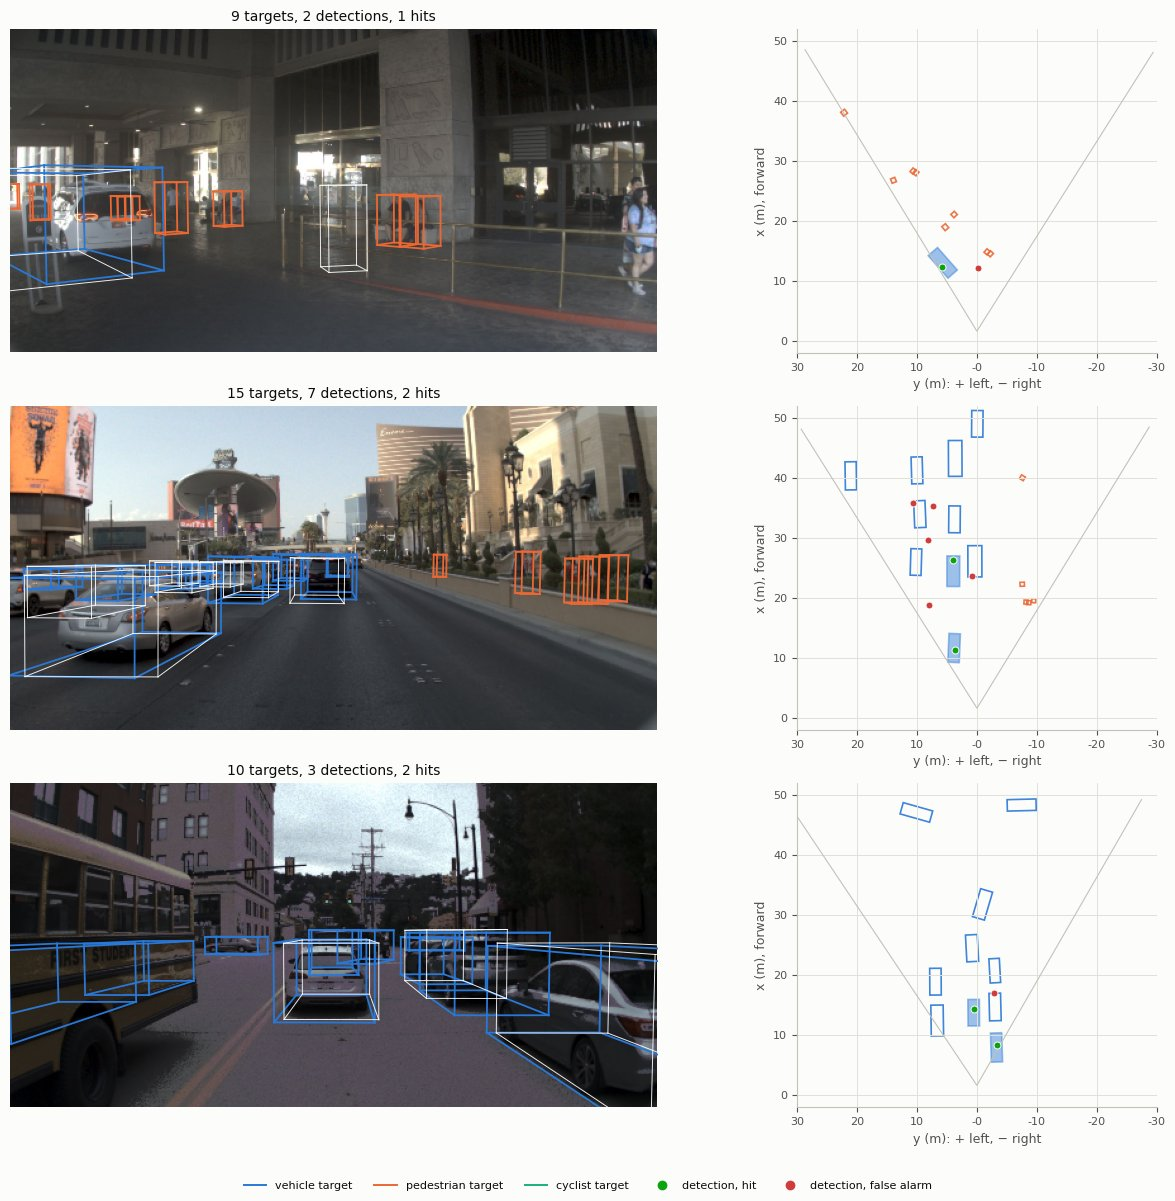

In [3]:
def freest_device():
    if not torch.cuda.is_available():
        return torch.device("cpu")
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    return torch.device("cuda", int(np.argmax(free)))


def raw_outputs(model, rows_, device, batch=128):
    """The last layer's raw outputs, batched as `train_sidecar.predict` batches them (fp16 on a GPU)."""
    model = model.to(device).eval()
    out = {k: [] for k in ("logits", "box", "vel", "path")}
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        for i in range(0, len(rows_), batch):
            chunk = rows_[i : i + batch]
            tok = torch.from_numpy(np.stack([np.asarray(vit[r], dtype=np.float16) for r in chunk])).to(device)
            if device.type == "cpu":
                tok = tok.float()
            o = model(tok, torch.from_numpy(proj[chunk]).to(device))[-1]
            for k in out:
                out[k].append(o[k].float().cpu().numpy())
    return {k: np.concatenate(v) for k, v in out.items()}


device = freest_device()
raw = raw_outputs(model, select, device)
preds = [evaluate.decode({k: v[i] for k, v in raw.items()}) for i in range(len(select))]
gts = [targets_of(r) for r in select]
print("ran on", device.type, "| outputs:", {k: v.shape for k, v in raw.items()})


def decoded_boxes(i):
    """Slot boxes in the labels' terms: x, y, z, l, w, h, yaw."""
    b = raw["box"][i]
    return np.c_[b[:, :3], np.exp(b[:, 3:6]), np.arctan2(b[:, 6], b[:, 7])]


def show(ax_img, ax_bev, i):
    r = select[i]
    frame = views.window_frames(NAVSIM, str(token_logs[r]), str(labels["token"][r]))[navsim_data.CURRENT]
    image = views.model_view(views.read_image(views.camera_path(NAVSIM, frame)))
    gt, pred = gts[i], preds[i]
    m = gt["mask"]
    det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    ax_img.imshow(image)
    for k in np.flatnonzero(m):
        for (u0, v0), (u1, v1) in views.box_edges_2d(proj[r], gt["box"][k][None])[0]:
            ax_img.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[gt["cls"][k]], lw=1.3)
    boxes = decoded_boxes(i)
    for q in det:
        for (u0, v0), (u1, v1) in views.box_edges_2d(proj[r], boxes[q][None])[0]:
            ax_img.plot([u0, u1], [v0, v1], color="white", lw=0.7, alpha=0.9)
    ax_img.set_xlim(0, 512)
    ax_img.set_ylim(256, 0)
    ax_img.axis("off")
    ax_img.set_title(f"{int(m.sum())} targets, {len(det)} detections, {int(tp.sum())} hits")
    edges = views.view_edges(proj[r], reach=55)
    ax_bev.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.AXIS, lw=0.8)
    for j, k in enumerate(np.flatnonzero(m)):
        outline = views.footprint(gt["box"][k][None])[0]
        colour = views.CLASS_COLOURS[gt["cls"][k]]
        ax_bev.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, ec=colour, lw=1.2,
                                 fc=colour if hit[j] >= 0 else "none", alpha=0.9 if hit[j] < 0 else 0.45))
    for q, ok in zip(det, tp):
        ax_bev.plot(-pred["xyz"][q, 1], pred["xyz"][q, 0], "o", ms=5, color=views.HIT if ok else views.MISS,
                    mec=views.SURFACE, mew=0.7)
    ax_bev.set_xlim(-30, 30)
    ax_bev.set_ylim(-2, 52)
    ax_bev.set_aspect("equal")
    y_axis_left(ax_bev)


rng = np.random.default_rng(4)
shown = [i for i in rng.permutation(len(select)) if 4 <= gts[i]["mask"].sum() <= 20][:3]
fig, axes = plt.subplots(3, 2, figsize=(13, 12), gridspec_kw={"width_ratios": [2.0, 1.0]})
for (ax_img, ax_bev), i in zip(axes, shown):
    show(ax_img, ax_bev, i)
handles = [plt.Line2D([], [], color=c, lw=1.4, label=f"{n} target") for n, c in zip(views.CLASS_NAMES, views.CLASS_COLOURS)]
handles += [plt.Line2D([], [], marker="o", ls="", color=views.HIT, label="detection, hit"),
            plt.Line2D([], [], marker="o", ls="", color=views.MISS, label="detection, false alarm")]
fig.legend(handles=handles, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
views.show_jpeg(fig)

## 3. The current readout, reproduced from the checkpoint

`evaluate.readout` on these outputs must give exactly what the run wrote at the end of epoch 1
(`metrics.jsonl`): same checkpoint, same rows, same batching. If it does not, the readout and the run
disagree about what they measure.

In [4]:
mine = evaluate.readout(preds, gts, run["prior_gap_m"])
keys = ["recall_2m_within_30m", "precision_2m_within_30m", "recall_by_range", "recall_2m_within_30m_by_class",
        "centre_error_m", "velocity_error_mps", "moving_vehicles_20m_recall", "lead_gap_mae_m",
        "path_fde_1s_model_moving", "path_fde_1s_cv_pred_moving", "targets"]
compare = pd.DataFrame({"recomputed here": [mine[k] for k in keys], "the run's metrics.jsonl": [recorded["select"][k] for k in keys]}, index=keys)
compare

,recomputed here,the run's metrics.jsonl
recall_2m_within_30m,0.405,0.405
precision_2m_within_30m,0.578,0.578
recall_by_range,"[0.6379853095487933, 0.2554317235168299, 0.080...","[0.6379853095487933, 0.2554317235168299, 0.080..."
recall_2m_within_30m_by_class,"[0.5325443786982249, 0.2413793103448276, 0.078...","[0.5325443786982249, 0.2413793103448276, 0.078..."
centre_error_m,1.029,1.029
velocity_error_mps,0.629,0.629
moving_vehicles_20m_recall,0.818,0.818
lead_gap_mae_m,4.258,4.258
path_fde_1s_model_moving,1.472,1.472
path_fde_1s_cv_pred_moving,1.47,1.47


In [5]:
def same(a, b):
    return np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), rtol=0, atol=1e-9, equal_nan=True)


assert all(same(mine[k], recorded["select"][k]) for k in keys), "the readout does not reproduce the run's"
print("every readout number above equals the run's own, to 1e-9")

every readout number above equals the run's own, to 1e-9


## 4. The proposed metrics, prototyped

Each is written here in a few lines so it can be reviewed before it is adopted. An adopted one moves into
`evaluate.py` with tests at step 6; this notebook's version is the prototype, not the record. All numbers
below are the pipeline check's (epoch 1 of 12, select logs).

### 4a. Average precision: does the side-car rank its guesses well, whatever the threshold?

Recall and precision at confidence 0.5 depend on 0.5 being the right threshold. **AP** sorts every slot of
a class by confidence, matches greedily (as above, at a radius), and averages precision over recall
(101 points, interpolated; nuScenes' convention ranks detections the same way). Within 30 m: targets by
their range, detections by theirs.

In [6]:
NONE = tg.NONE


def softmax(logits):
    e = np.exp(logits - logits.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)


prob = softmax(raw["logits"])
conf_all, cls_all = 1.0 - prob[..., NONE], prob[..., :NONE].argmax(-1)


def average_precision(cls_k, radius, max_range=30.0, floor=0.01):
    dets, gt_xy = [], []
    for i, gt in enumerate(gts):
        m = gt["mask"] & (gt["cls"] == cls_k)
        g = gt["box"][m, :2]
        gt_xy.append(g[np.hypot(g[:, 0], g[:, 1]) < max_range])
        sel = (cls_all[i] == cls_k) & (conf_all[i] >= floor)
        p = raw["box"][i, sel, :2]
        near = np.hypot(p[:, 0], p[:, 1]) < max_range
        dets += [(c, i, xy_) for c, xy_ in zip(conf_all[i, sel][near], p[near])]
    n_gt = sum(len(g) for g in gt_xy)
    dets.sort(key=lambda d: -d[0])
    used = [np.zeros(len(g), bool) for g in gt_xy]
    tp = np.zeros(len(dets))
    for k, (_, i, xy_) in enumerate(dets):
        if not len(gt_xy[i]):
            continue
        d = np.hypot(*(gt_xy[i] - xy_).T)
        d[used[i]] = np.inf
        g = int(np.argmin(d))
        if d[g] <= radius:
            used[i][g], tp[k] = True, 1
    hits = np.cumsum(tp)
    precision, recall = hits / np.arange(1, len(tp) + 1), hits / max(n_gt, 1)
    ap = np.mean([precision[recall >= r].max() if (recall >= r).any() else 0.0 for r in np.linspace(0, 1, 101)])
    return ap, recall, precision, n_gt


ap_table, curves = {}, {}
for c, name in enumerate(views.CLASS_NAMES):
    ap_table[name] = {}
    for radius in (0.5, 1.0, 2.0, 4.0):
        ap, recall, precision, n_gt = average_precision(c, radius)
        ap_table[name][f"AP at {radius:g} m"] = ap
        if radius == 2.0:
            curves[name] = (recall, precision)
    ap_table[name]["targets within 30 m"] = n_gt
pd.DataFrame(ap_table)

,vehicle,pedestrian,cyclist
AP at 0.5 m,0.054,0.015,0.002
AP at 1 m,0.246,0.084,0.065
AP at 2 m,0.581,0.296,0.155
AP at 4 m,0.813,0.548,0.195
targets within 30 m,8281.000,6206.000,114.000


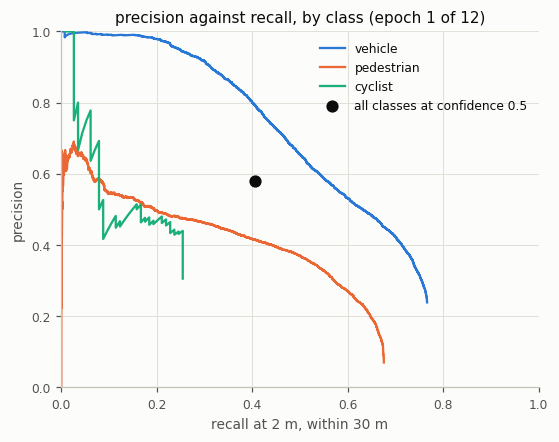

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
for c, name in enumerate(views.CLASS_NAMES):
    recall, precision = curves[name]
    ax.plot(recall, precision, color=views.CLASS_COLOURS[c], label=name)
r_thr, p_thr = recorded["select"]["recall_2m_within_30m"], recorded["select"]["precision_2m_within_30m"]
ax.plot(r_thr, p_thr, "o", ms=7, color=views.INK, label="all classes at confidence 0.5")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("recall at 2 m, within 30 m")
ax.set_ylabel("precision")
ax.set_title("precision against recall, by class (epoch 1 of 12)")
ax.legend(loc="upper right")
plt.show()

### 4b. Boxes and motion of the hits: z, size, yaw, velocity, and motion apart from position

For every hit at the readout's threshold. **Size error** is 1 − IoU of the two boxes aligned on the same
centre and yaw (nuScenes' ASE): it scores the dimensions only. **Yaw error** is the absolute angle
difference, wrapped to 0–180°. **Displacement error** compares where the side-car sends the agent in 1 s
(path offset at +1 s) with where the label sends it, both from their own centres: motion without the
position error, which the path FDE in the readout mixes in.

In [8]:
records = []
for i, (gt, pred) in enumerate(zip(gts, preds)):
    m = gt["mask"]
    det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    boxes = decoded_boxes(i)
    for j, q in enumerate(hit):
        if q < 0:
            continue
        k = np.flatnonzero(m)[j]
        g = gt["box"][k]
        lwh_p, lwh_g = boxes[q, 3:6], g[3:6]
        inter = np.prod(np.minimum(lwh_p, lwh_g))
        iou = inter / (np.prod(lwh_p) + np.prod(lwh_g) - inter)
        dyaw = abs((boxes[q, 6] - g[6] + np.pi) % (2 * np.pi) - np.pi)
        speed = float(np.hypot(*gt["vel"][k]))
        ok = bool(gt["path_ok"][k, 1])
        records.append({
            "class": views.CLASS_NAMES[gt["cls"][k]],
            "range": float(np.hypot(*g[:2])),
            "centre error (m)": float(np.hypot(*(boxes[q, :2] - g[:2]))),
            "z error (m)": float(abs(boxes[q, 2] - g[2])),
            "size error (1 − IoU)": float(1 - iou),
            "yaw error (°)": float(np.degrees(dyaw)),
            "velocity error (m/s)": float(np.hypot(*(raw["vel"][i, q] - gt["vel"][k]))),
            "velocity error of 'it stands still' (m/s)": speed,
            "moving": speed > evaluate.MOVING_MPS,
            "displacement error at 1 s (m)": float(np.hypot(*(raw["path"][i, q, 1] - gt["path"][k, 1]))) if ok else np.nan,
            "displacement error, constant velocity (its own) (m)": float(np.hypot(*(raw["vel"][i, q] - gt["path"][k, 1]))) if ok else np.nan,
            "displacement error, constant velocity (the label's) (m)": float(np.hypot(*(gt["vel"][k] - gt["path"][k, 1]))) if ok else np.nan,
        })
hits_df = pd.DataFrame(records)
print(f"{len(hits_df):,} hits on select")
hits_df.groupby("class")[["centre error (m)", "z error (m)", "size error (1 − IoU)", "yaw error (°)",
                          "velocity error (m/s)", "velocity error of 'it stands still' (m/s)"]].mean().T

7,346 hits on select


class,cyclist,pedestrian,vehicle
centre error (m),1.059,1.111,0.994
z error (m),0.098,0.153,0.123
size error (1 − IoU),0.310,0.139,0.188
yaw error (°),3.508,72.410,6.723
velocity error (m/s),1.436,0.904,0.510
velocity error of 'it stands still' (m/s),4.239,0.915,2.107


In [9]:
moving = hits_df[hits_df.moving]
pd.DataFrame({
    "moving hits": [len(moving)],
    "side-car's path (m)": [moving["displacement error at 1 s (m)"].mean()],
    "constant velocity, its own velocity (m)": [moving["displacement error, constant velocity (its own) (m)"].mean()],
    "constant velocity, the label's velocity (m)": [moving["displacement error, constant velocity (the label's) (m)"].mean()],
}, index=["displacement error at 1 s, mean"]).T

,"displacement error at 1 s, mean"
moving hits,3623.000
side-car's path (m),1.069
"constant velocity, its own velocity (m)",1.087
"constant velocity, the label's velocity (m)",0.403


Read beside the readout's path FDE for the same agents (1.47 m, section 3), the displacement error shows
how much of that FDE is position and how much is motion.

### 4c. Calibration: does a confidence of 0.7 mean 70% of those slots are right?

Every slot of confidence at least 0.1, matched greedily as above, binned by confidence. Phase B (if it
opens) reads a thresholded list, so what the threshold means matters.

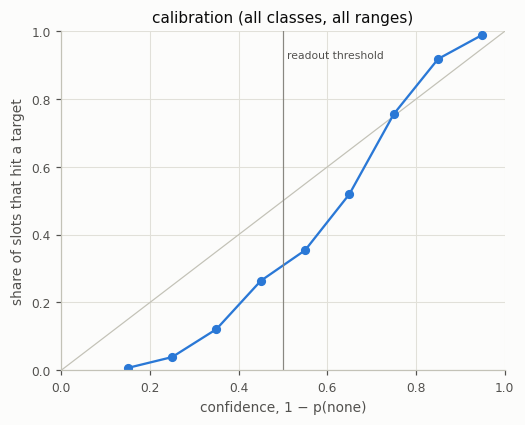

,0.1–0.2,0.2–0.3,0.3–0.4,0.4–0.5,0.5–0.6,0.6–0.7,0.7–0.8,0.8–0.9,0.9–1.0
slots,90377.000,57996.000,42454.000,24752.000,8861.000,3116.00,873.000,1021.000,1000.00
hit rate,0.007,0.039,0.121,0.264,0.354,0.52,0.756,0.919,0.99


In [10]:
bins = np.linspace(0.1, 1.0, 10)
hit_by_bin = np.zeros(len(bins) - 1)
n_by_bin = np.zeros(len(bins) - 1)
for i, gt in enumerate(gts):
    m = gt["mask"]
    keep = conf_all[i] >= 0.1
    order = np.flatnonzero(keep)[np.argsort(-conf_all[i][keep], kind="stable")]
    free = np.ones(int(m.sum()), bool)
    gxy, gcls = gt["box"][m, :2], gt["cls"][m]
    for q in order:
        d = np.hypot(*(gxy - raw["box"][i, q, :2]).T) if len(gxy) else np.zeros(0)
        d[~free | (gcls != cls_all[i, q])] = np.inf
        ok = len(d) and d.min() <= evaluate.HIT_M
        if ok:
            free[int(np.argmin(d))] = False
        b = min(np.searchsorted(bins, conf_all[i, q], side="right") - 1, len(bins) - 2)
        n_by_bin[b] += 1
        hit_by_bin[b] += ok
centres = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(5.2, 4.0))
ax.plot([0, 1], [0, 1], color=views.AXIS, lw=0.8)
ax.plot(centres, hit_by_bin / np.maximum(n_by_bin, 1), "o-", color=views.CLASS_COLOURS[0], ms=5)
ax.axvline(evaluate.THR, color=views.GREY, lw=0.8)
ax.text(evaluate.THR + 0.01, 0.92, "readout threshold", fontsize=7, color=views.INK_2)
ax.set_xlabel("confidence, 1 − p(none)")
ax.set_ylabel("share of slots that hit a target")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("calibration (all classes, all ranges)")
plt.show()
pd.DataFrame({"slots": n_by_bin.astype(int), "hit rate": hit_by_bin / np.maximum(n_by_bin, 1)},
             index=[f"{a:.1f}–{b:.1f}" for a, b in zip(bins[:-1], bins[1:])]).T

### 4d. Breakdowns: by city and by ego speed

Recall and precision within 30 m, at the threshold, per sample's city and per ego speed band. Select has
only 2 Singapore logs; report has 8 (plan §3.5), which is why the breakdown matters there.

In [11]:
import pickle


def city(log_name):
    with open(NAVSIM / "navsim_logs" / "trainval" / f"{log_name}.pkl", "rb") as fh:
        return pickle.load(fh)[0]["map_location"]


cities = {log_name: city(log_name) for log_name in splits["select"]}
ego = np.asarray(np.load(RUNS / "tokens-v1" / "ego_status.npy", mmap_mode="r")[select, -1, 3:5])
ego_speed = np.hypot(ego[:, 0], ego[:, 1])
per_sample = []
for i, (gt, pred) in enumerate(zip(gts, preds)):
    m = gt["mask"]
    det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    g_near = np.hypot(gt["box"][m, 0], gt["box"][m, 1]) < 30
    d_near = np.hypot(pred["xyz"][det, 0], pred["xyz"][det, 1]) < 30
    per_sample.append({
        "log": token_logs[select[i]],
        "city": cities[token_logs[select[i]]],
        "ego speed": "stopped (< 0.5 m/s)" if ego_speed[i] < 0.5 else ("< 5 m/s" if ego_speed[i] < 5 else "≥ 5 m/s"),
        "targets": int(g_near.sum()), "hits": int((g_near & (hit >= 0)).sum()),
        "detections": int(d_near.sum()), "true": int((d_near & tp).sum()),
    })
per_sample = pd.DataFrame(per_sample)


def rates(g):
    return pd.Series({"logs": g.log.nunique(), "samples": len(g), "targets": g.targets.sum(),
                      "recall": g.hits.sum() / max(g.targets.sum(), 1), "precision": g.true.sum() / max(g.detections.sum(), 1)})


pd.concat({"city": per_sample.groupby("city").apply(rates), "ego speed": per_sample.groupby("ego speed").apply(rates)})

logs  samples  targets  recall  \
city      sg-one-north                 2.0    390.0    106.0   0.217   
          us-ma-boston                 9.0    583.0   1149.0   0.377   
          us-nv-las-vegas-strip       33.0   2958.0  12820.0   0.411   
          us-pa-pittsburgh-hazelwood   7.0    526.0    526.0   0.356   
ego speed < 5 m/s                     48.0   2086.0   9418.0   0.428   
          stopped (< 0.5 m/s)         42.0    397.0   1501.0   0.453   
          ≥ 5 m/s                     48.0   1974.0   3682.0   0.328   

                                      precision  
city      sg-one-north                    0.697  
          us-ma-boston                    0.656  
          us-nv-las-vegas-strip           0.573  
          us-pa-pittsburgh-hazelwood      0.554  
ego speed < 5 m/s                         0.564  
          stopped (< 0.5 m/s)             0.625  
          ≥ 5 m/s                         0.605

## 5. Uncertainty: resampling whole logs

A log's samples are 0.5 s apart and nearly the same, so they are not independent: an interval that
resamples samples would be far too narrow. Resampling the **logs** (with replacement, 1,000 draws) and
recomputing recall from their samples gives an honest 95% interval. With 51 select logs:

In [12]:
by_log = per_sample.groupby("log")[["targets", "hits", "detections", "true"]].sum()
rng = np.random.default_rng(0)
draws = rng.integers(0, len(by_log), size=(1000, len(by_log)))
values = by_log.values
recall_draws = values[draws, 1].sum(1) / values[draws, 0].sum(1)
precision_draws = values[draws, 3].sum(1) / values[draws, 2].sum(1)
point = per_sample.hits.sum() / per_sample.targets.sum()
pd.DataFrame({
    "point": [point, per_sample.true.sum() / per_sample.detections.sum()],
    "95% interval, logs resampled": [f"{np.percentile(recall_draws, 2.5):.3f}–{np.percentile(recall_draws, 97.5):.3f}",
                                     f"{np.percentile(precision_draws, 2.5):.3f}–{np.percentile(precision_draws, 97.5):.3f}"],
}, index=["recall within 30 m", "precision within 30 m"])

,point,"95% interval, logs resampled"
recall within 30 m,0.405,0.373–0.442
precision within 30 m,0.578,0.536–0.614


The interval's width (a few points of recall) is the scale on which step 5's choices are made; the plan's
0.01-F1 rule for choosing a variant is below it on purpose. The rule compares variants **on the same select
logs**, whose shared log effects cancel in the difference, and the seed spread decides whether a
difference is a choice or noise.

## 6. The sight check, in distribution

Does the side-car read the image, or has it learnt where agents usually are? Each select sample keeps its
own camera geometry and targets, but reads the **tokens of a sample from another log** (the S arm's
seeded draw, `train_scorer.shuffled_rows`). A side-car that reads the image loses its recall; one that
guesses from habit keeps it. (The first pass's zeroed-token check fed an input no run had seen;
this one feeds real tokens of the wrong scene.)

In [13]:
from gallops.drivejepa_perception.train_scorer import shuffled_rows

other = shuffled_rows(token_logs)
print(f"share of select samples given another log's tokens: {(token_logs[other[select]] != token_logs[select]).mean():.0%}")


def raw_from(rows_tokens, rows_geometry, device, batch=128):
    model.to(device).eval()
    out = {k: [] for k in ("logits", "box", "vel", "path")}
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        for i in range(0, len(rows_tokens), batch):
            tok = torch.from_numpy(np.stack([np.asarray(vit[r], dtype=np.float16) for r in rows_tokens[i:i + batch]])).to(device)
            if device.type == "cpu":
                tok = tok.float()
            o = model(tok, torch.from_numpy(proj[rows_geometry[i:i + batch]]).to(device))[-1]
            for k in out:
                out[k].append(o[k].float().cpu().numpy())
    return {k: np.concatenate(v) for k, v in out.items()}


swapped = raw_from(other[select], select, device)
preds_swapped = [evaluate.decode({k: v[i] for k, v in swapped.items()}) for i in range(len(select))]
swap = evaluate.readout(preds_swapped, gts, run["prior_gap_m"])
pd.DataFrame({
    "own tokens": [mine["recall_2m_within_30m"], mine["precision_2m_within_30m"], np.mean([(p["conf"] >= 0.5).sum() for p in preds])],
    "another log's tokens": [swap["recall_2m_within_30m"], swap["precision_2m_within_30m"], np.mean([(p["conf"] >= 0.5).sum() for p in preds_swapped])],
}, index=["recall within 30 m", "precision within 30 m", "detections per sample"])

share of select samples given another log's tokens: 100%


,own tokens,another log's tokens
recall within 30 m,0.405,0.031
precision within 30 m,0.578,0.048
detections per sample,3.337,3.140


Plan Q6 asks, on the report logs and at the kept epoch, for recall with another log's tokens at most 0.10.
After one epoch, on select, the drop is already the expected shape.

## 7. nuScenes, out of the box (step 7): the plan

**Why.** Neither the side-car nor the released model ever saw nuScenes: it is the one clean out-of-sample
check H15 has. The camera is nearly NAVSIM's (read in both datasets' calibration; plan §8.2):

| | NAVSIM CAM_F0 | nuScenes CAM_FRONT |
|---|---|---|
| image | 1920×1080 | 1600×900 |
| focal length on the 512×256 token image, x / y | 412 / 386 px | 401–405 / 380–384 px |
| horizontal field of view | 63.7° | 64.6–65.1° |
| mounting: forward, up from the ego origin | 1.62–1.67, 1.52 m | 1.67–1.72, 1.49–1.54 m |

so the gap is mostly the image itself (a 2018 camera, other streets) and the labels (human, with a
lidar-point filter, against auto-labels with none).

**The geometry** goes through `targets.to_512(width, height)`, which composes the vendor's 0.4 scaling, the
28-row crop and the resize for any camera:

In [14]:
np.set_printoptions(precision=4, suppress=True)
print("NAVSIM (1920×1080) — equals TO_512:", np.allclose(tg.to_512(1920, 1080), tg.TO_512))
print(tg.to_512(1920, 1080)[:2])
print("nuScenes (1600×900):")
print(tg.to_512(1600, 900)[:2])

NAVSIM (1920×1080) — equals TO_512: True
[[ 0.6667  0.      0.      0.    ]
 [ 0.      0.625  -7.      0.    ]]
nuScenes (1600×900):
[[ 0.8     0.      0.      0.    ]
 [ 0.      0.7583 -8.4929  0.    ]]


**Classes** (`ood.CATEGORY_CLASS`, the first matching prefix wins), and only annotations at least one lidar
point hit (`ood.MIN_LIDAR_POINTS`):

In [15]:
from gallops.drivejepa_perception import ood

pd.DataFrame([(prefix + "*", navsim_data.CLASSES[c]) for prefix, c in ood.CATEGORY_CLASS],
             columns=["nuScenes category", "H15 class"]).set_index("nuScenes category").T

nuScenes category,vehicle.bicycle*,vehicle.motorcycle*,vehicle.*,human.pedestrian.*,movable_object.barrier*,movable_object.trafficcone*
H15 class,cyclist,cyclist,vehicle,pedestrian,static,static


**Steps** (each a recipe stage that exists, except the last):
1. the site's nuScenes root (`[datasets.nuscenes]`: `v1.0-trainval/`, `samples/`, `can_bus/`). Its state at
   this site is printed below;
2. `ood-draw --n 100 --seed 0`: 100 nuScenes **train** scenes with CAN-bus poses, none behind a neuroNCAP or
   reconstructed scenario (val is paddock's benchmark), committed once;
3. `ood-extract`, then `ood-pass`: every usable keyframe (about 3,000) through the release at batch 1, its
   ViT output kept, its projection held to the calibration within 0.5 px;
4. a side-car-only readout (written at step 7): every metric above, per class and range, by location
   (Boston seaport, Singapore one-north, Queenstown, Holland Village), night and rain apart.

**Success** is the plan's Q9: vehicle recall at 2 m within 30 m of at least 0.30.

In [16]:
try:
    root = Path(cfg.resolve("{data.nuscenes}"))
    present = {name: (root / name).exists() for name in ("v1.0-trainval", "samples", "can_bus")}
    print("nuScenes root configured; present:", present)
except Exception as error:  # the config names a root that does not exist at this site
    print("nuScenes is not usable at this site yet:", type(error).__name__, "(step 7.1: configure its root)")

nuScenes is not usable at this site yet: ConfigError (step 7.1: configure its root)


## Summary for the review

1. **The readout reproduces the run's own numbers exactly** from the saved checkpoint (section 3): what
   step 6 reports is what the runs recorded.
2. **Five additions are proposed** (AP, box and yaw errors, displacement error, calibration, breakdowns),
   each prototyped above on real outputs. They cost no training; adopting them is the owner's call
   (plan §11 Q4).
3. **Intervals resample whole logs**; differences between variants are read on the same logs, against the
   seed spread.
4. **The sight check** feeds real tokens of the wrong scene; it already separates after one epoch.
5. **nuScenes needs its site root first**; the camera is close enough to NAVSIM's that the geometry is not
   the question, the image and the labels are.